# Import Packages

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Read Data

In [9]:
data = pd.read_csv("../../data/raw/PoemDataset.csv")

In [10]:
print(len(data))

10000


In [11]:
data.head()

,Title,Poem,Poet,Genre
0,Search,Wandered tonight through a cityas ruined as a ...,Hester Knibbe,Fear
1,A Poem for the Cruel Majority,The cruel majority emerges!Hail to the cruel m...,Jerome Rothenberg,Anger
2,“Do Not Embrace Your Mind’s New Negro Friend”,Do not embrace your mind’s new negro friendOr ...,William Meredith,Anger
3,The Greatest Love,She is sixty. She livesthe greatest love of he...,Anna Swir,Love
4,Bilingual/Bilingüe,"My father liked them separate, one there,one h...",Rhina P. Espaillat,Anger


In [12]:
data.dtypes

Title    object
Poem     object
Poet     object
Genre    object
dtype: object

# Missing

In [13]:
data.isna().sum()

Title     1
Poem     72
Poet      0
Genre     0
dtype: int64

In [14]:
data[data.isna().any(axis=1)]

,Title,Poem,Poet,Genre
197,Sonata for soprano saxophone,NaN,Gary Barwin,Anger
431,from The Woman’s Labor. An Epistle to Mr Steph...,NaN,Mary Collier,Anger
614,Imogen and the Beginning of Color (an Excerpt),NaN,Gabrielle Bates,Anger
711,The Apparition,NaN,Herman Melville,Anger
1129,"""Ashamed to ask why...""",NaN,Stephen Dobyns,Anger
...,...,...,...,...
9189,Poet's Wish,NaN,William Jay Smith,Anger
9243,"From ""TEST""",NaN,Dora Malech,Anger
9253,Imagined Room,NaN,Barbara Guest,Anger
9822,I will never leave thee nor forsake thee,NaN,Ian Williams,Anger


In [15]:
data.dropna(inplace=True)
data.isna().sum()
print(len(data))

9927


# Length Histograms

1 203


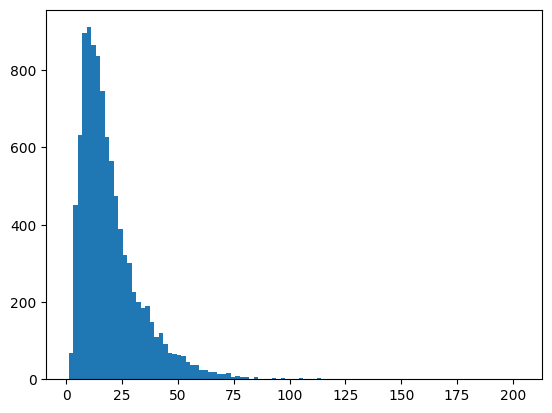

In [16]:
# Title
title_length = data["Title"].str.len()
plt.hist(title_length, bins=100)
print(min(title_length), max(title_length))

1 203


np.float64(0.08139417749571874)

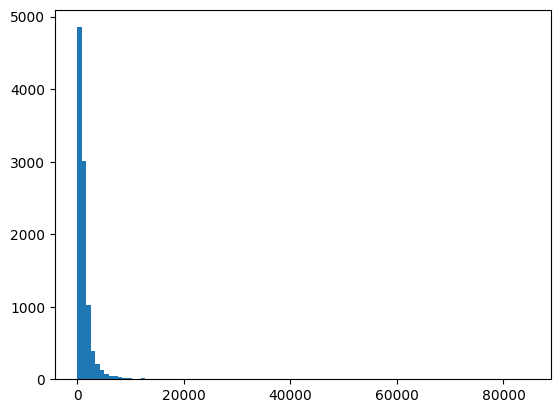

In [17]:
#poems
poem_length = data["Poem"].str.len()
plt.hist(poem_length, bins=100)
print(min(poem_length), max(title_length))

(poem_length > 3000).sum() / len(poem_length)

# Drop Too long poems

In [18]:
print(len(data))
data = data[data["Poem"].str.len() < 3000]
print(len(data))


9927
9119


In [19]:
#data.to_csv("../../data/processed/trial_processed.csv")

# Read Some Poems

In [24]:
index = 4
print(data.iloc[index,0])
print(data.iloc[index,1])
print(data.iloc[index,2])
print(data.iloc[index,3])

Bilingual/Bilingüe
My father liked them separate, one there,one here (allá y aquí), as if awarethat words might cut in two his daughter’s heart(el corazón) and lock the alien partto what he was—his memory, his name(su nombre)—with a key he could not claim.“English outside this door, Spanish inside,”he said, “y basta.” But who can dividethe world, the word (mundo y palabra) fromany child? I knew how to be dumband stubborn (testaruda); late, in bed,I hoarded secret syllables I readuntil my tongue (mi lengua) learned to runwhere his stumbled. And still the heart was one.I like to think he knew that, even when,proud (orgulloso) of his daughter’s pen,he stood outside mis versos, half in fearof words he loved but wanted not to hear.
Rhina P. Espaillat
Anger


# For data cleaning
- get rid of missing data / na rows
- get rid of the really really long poems. Maybe greater than 5000 characters

In [21]:
import torch

In [22]:
fill = torch.tril(torch.ones(5, 5))

In [23]:
fill

tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])